Imports

In [1]:
import csv
import json
import time
from pathlib import Path

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights
import torch
import torch.nn as nn

from scripts.run_logger import RunLogger, new_run_config

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
weights = ResNet18_Weights.DEFAULT
print(device, weights.name)

cuda IMAGENET1K_V1


Dataset Class

In [2]:
class CrisisDataset(Dataset):
    def __init__(self, tsv_path, image_root, label_to_id):
        with open(tsv_path, encoding="utf-8", newline="") as f:
            self.rows = list(csv.DictReader(f, delimiter="\t"))

        self.image_root = Path(image_root)
        self.label_to_id = label_to_id

        self.transform = ResNet18_Weights.DEFAULT.transforms()

    def __len__(self):
        return (len(self.rows))

    def __getitem__(self, index):
        row = self.rows[index]

        with Image.open(self.image_root / row["image"]) as image:
            image = self.transform(image.convert("RGB"))

        return {
            "text" : row["tweet_text"],
            "image" : image,
            "label" : self.label_to_id[row["label"]],
            "tweet_id" : row["tweet_id"],
            "image_id" : row["image_id"]
        }

Data Loaders

In [3]:
root = Path("data/crisismmd")
label_to_id = {"not_informative": 0, "informative": 1}

datasets = {
    split: CrisisDataset(
        tsv_path=root / "prepared" / "informative" / f"{split}.tsv",
        image_root=root,
        label_to_id=label_to_id,
    )
    for split in ("train", "valid", "test")
}

train_loader = DataLoader(
    datasets["train"], batch_size=64, shuffle=True, num_workers=0
)
valid_loader = DataLoader(
    datasets["valid"], batch_size=64, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    datasets["test"], batch_size=64, shuffle=False, num_workers=0
)

# Only reads the TSVs; loading images and the forward-pass check happen in the
# logged debug run below, so all model computation sits inside a measured run.
print({split: len(ds) for split, ds in datasets.items()})
# {'train': 9601, 'valid': 1573, 'test': 1534}

{'train': 9601, 'valid': 1573, 'test': 1534}


**Idle baseline (fixed background power).** Every run uses CodeCarbon *machine* mode, which includes the computer's background draw: idle CPU, the GPU driving the display, and RAM. Run this once per machine and session. Close TensorBoard and other heavy programs first, and don't touch the computer for the 60 seconds. Its average power is the fixed component used to separate fixed from data-dependent energy in the 10×/100× scaling analysis.

In [4]:
baseline_config = new_run_config("templates/idle_baseline_config.json", "A_idle_baseline")

with RunLogger(baseline_config) as run:
    time.sleep(run.config["baseline_seconds"])

print(run.describe())

[codecarbon INFO @ 14:42:44] offline tracker init
[codecarbon WARNING @ 14:42:44] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon INFO @ 14:42:44] Using forced carbon intensity: 122.0 gCO2e/kWh.
[codecarbon INFO @ 14:42:44] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/logs/runs/A_idle_baseline_20261122T144244_d99585ea/energy.csv
[codecarbon INFO @ 14:42:44] [setup] RAM Tracking...
[codecarbon INFO @ 14:42:44] [setup] CPU Tracking...
[codecarbon INFO @ 14:42:44] [setup] GPU Tracking...
[codecarbon INFO @ 14:42:44] Tracking Intel CPU via RAPL interface
[codecarbon INFO @ 14:42:44] Tracking Nvidia GPUs via PyNVML
[codecarbon WARNING @ 14:42:45] 	RAPL - Permission denied reading RAPL file /sys/class/powercap/intel-rapl/subsystem/intel-rapl:0/intel-rapl:0:0/energy_uj. You can grant read permission with: sudo chmod -R a+r /sys/class/powercap/* (this does not persist across reboots, see https://

A_idle_baseline_20261122T144244_d99585ea: completed (run_type=debug, stage=development)
  logs: logs/runs/A_idle_baseline_20261122T144244_d99585ea
  runtime 61.3 s (tracker 60.0 s)
  energy 0.001268 kWh, range 0.000943 to 0.001682
  emissions 0.000155 kgCO2e, range 0.000089 to 0.000400 (central 122 gCO2/kWh)
  average power: CPU 35.9 W, GPU 19.8 W, RAM 20.0 W
  method: CodeCarbon 3.3.2 OfflineEmissionsTracker, tracking_mode=machine; CPU: measured (intel_rapl package energy counter); GPU: measured (GPU driver energy counter (pynvml/amdsmi)); RAM: estimated (CodeCarbon heuristic, 5 W per estimated DIMM)


**Debug run: freeze ResNet18 and test one forward pass.** This checks the architecture: it loads the frozen encoder, reads one training batch and checks for a 512-d output. The guidance places debug runs and architecture checks inside the reporting boundary, so this is logged as `run_type="debug"`.

In [5]:
def build_image_encoder():
    """Frozen ImageNet ResNet18 with the final layer replaced by identity (512-d output)."""
    encoder = resnet18(weights=weights)
    encoder.fc = nn.Identity()
    encoder.requires_grad_(False)
    encoder.eval()
    return encoder.to(device)


smoke_config = new_run_config(
    "templates/feature_extraction_config.json", "A_resnet18_smoke_debug",
    run_type="debug",
    workflow_stage="development",
    activity="debug_forward_pass",
    training_examples=len(datasets["train"]),
    measurement_boundary=(
        "Loading pretrained ResNet18, reading/preprocessing one training batch and one forward "
        "pass to check the 512-d output; no cache written. CodeCarbon machine mode includes "
        "background power (see idle-baseline run)."
    ),
    reuse_notes="Not applicable: architecture check only; no artefacts produced.",
    notes="Debug check before feature extraction.",
)

with RunLogger(smoke_config) as run:
    image_encoder = build_image_encoder()
    assert not any(p.requires_grad for p in image_encoder.parameters())
    run.update(trainable_parameters=0)
    batch = next(iter(train_loader))
    with torch.no_grad():
        features = image_encoder(batch["image"].to(device))
    run.progress(split="train", batch=1, examples=len(batch["image"]))
    assert features.shape == (len(batch["image"]), 512), features.shape

print(features.shape)  # torch.Size([64, 512])
print(run.describe())

[codecarbon INFO @ 14:43:45] offline tracker init
[codecarbon WARNING @ 14:43:45] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon INFO @ 14:43:45] Using forced carbon intensity: 122.0 gCO2e/kWh.
[codecarbon INFO @ 14:43:45] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/logs/runs/A_resnet18_smoke_debug_20261122T144345_681946da/energy.csv
[codecarbon INFO @ 14:43:45] Monitoring GPUs with indices: [0] out of 1 total GPUs
[codecarbon WARNING @ 14:43:45] 	RAPL - Permission denied reading RAPL file /sys/class/powercap/intel-rapl/subsystem/intel-rapl:0/intel-rapl:0:0/energy_uj. You can grant read permission with: sudo chmod -R a+r /sys/class/powercap/* (this does not persist across reboots, see https://docs.codecarbon.io/latest/how-to/troubleshooting/#rapl-permission-denied for a permanent setup); skipping.
[codecarbon WARNING @ 14:43:45] 	RAPL - Permission denied reading RAPL file /sys/class/pow

torch.Size([64, 512])
A_resnet18_smoke_debug_20261122T144345_681946da: completed (run_type=debug, stage=development)
  logs: logs/runs/A_resnet18_smoke_debug_20261122T144345_681946da
  runtime 0.7 s (tracker 0.7 s)
  energy 0.000018 kWh, range 0.000014 to 0.000024
  emissions 0.000002 kgCO2e, range 0.000001 to 0.000006 (central 122 gCO2/kWh)
  average power: CPU 40.3 W, GPU 13.0 W, RAM 20.0 W
  method: CodeCarbon 3.3.2 OfflineEmissionsTracker, tracking_mode=machine; CPU: measured (intel_rapl package energy counter); GPU: measured (GPU driver energy counter (pynvml/amdsmi)); RAM: estimated (CodeCarbon heuristic, 5 W per estimated DIMM)


Cache ResNet features with the reusable run logger

Extraction uses `templates/feature_extraction_config.json` (workflow stage `artefact_production`) and the shared assumptions in `templates/measurement_method.json`: carbon intensity, PUE and uncertainty factors. Each execution of the extraction cell creates a unique experiment ID. Loading the model is inside the measured boundary. Feature extraction produces no training epochs, loss, learning rate or F1.


In [4]:
cache_dir = Path("data/crisismmd/features")
cache_dir.mkdir(parents=True, exist_ok=True)


@torch.no_grad()
def cache_features(dataset, split, run, encoder):
    loader = DataLoader(
        dataset, batch_size=run.config["batch_size"], shuffle=False, num_workers=0
    )
    feature_batches, label_batches = [], []
    image_ids, tweet_ids = [], []
    encoder.eval()

    for batch_index, batch in enumerate(loader, start=1):
        images = batch["image"].to(device)
        features = encoder(images)
        feature_batches.append(features.cpu())
        label_batches.append(batch["label"])
        image_ids.extend(batch["image_id"])
        tweet_ids.extend(batch["tweet_id"])
        run.progress(split=split, batch=batch_index, examples=len(images))

    cache = {
        "features": torch.cat(feature_batches),
        "labels": torch.cat(label_batches),
        "image_ids": image_ids,
        "tweet_ids": tweet_ids,
        "weights": weights.name,
        "label_to_id": dataset.label_to_id,
    }
    assert cache["features"].shape == (len(dataset), 512)
    output_path = cache_dir / f"informative_{split}.pt"
    torch.save(cache, output_path)
    print(split, cache["features"].shape, output_path)
    return str(output_path)


Before starting extraction, open a separate terminal in the coursework directory and run:

```bash
source .venv/bin/activate
tensorboard --logdir logs/runs --port 6006 --reload_interval 2
```

Open **http://localhost:6006**, select the new run, and view **Scalars**. Energy samples are written about once per second; allow a few seconds for the dashboard to refresh.
- `Energy/*` is cumulative kWh.
- `Power/*_w_interval` is the average watts over the last measurement interval.
- `Power/*_w_run_average` is the running average.

The energy charts use the measurement-sample number as their step; choose relative wall time to see elapsed time. Machine-mode tracking includes TensorBoard's own CPU load (declared in the measurement boundary), so keep it closed during the idle baseline. Each run's `summary.json` records whether CPU, GPU and RAM energy were measured or estimated.


In [7]:
# A new experiment ID for each attempt; earlier logs cannot be overwritten.
# If this repeats an earlier attempt, also pass rerun_of="<old experiment_id>" and rerun_reason="...".
extraction_config = new_run_config(
    "templates/feature_extraction_config.json", "A_resnet18_features",
    training_examples=len(datasets["train"]),
    split_examples={split: len(ds) for split, ds in datasets.items()},
)

with RunLogger(extraction_config) as run:
    image_encoder = build_image_encoder()  # model loading is inside the boundary
    assert not any(p.requires_grad for p in image_encoder.parameters())
    run.update(trainable_parameters=0)
    cache_paths = []
    for split in ("train", "valid", "test"):
        cache_paths.append(cache_features(datasets[split], split, run, image_encoder))
        run.update(cache_output_paths=list(cache_paths))

print(run.describe())
print("Images processed:", run.summary["examples_processed"])  # 12708


[codecarbon INFO @ 14:43:46] offline tracker init
[codecarbon WARNING @ 14:43:46] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon INFO @ 14:43:46] Using forced carbon intensity: 122.0 gCO2e/kWh.
[codecarbon INFO @ 14:43:46] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/logs/runs/A_resnet18_features_20261122T144346_28beeb48/energy.csv
[codecarbon INFO @ 14:43:46] Monitoring GPUs with indices: [0] out of 1 total GPUs
[codecarbon WARNING @ 14:43:46] 	RAPL - Permission denied reading RAPL file /sys/class/powercap/intel-rapl/subsystem/intel-rapl:0/intel-rapl:0:0/energy_uj. You can grant read permission with: sudo chmod -R a+r /sys/class/powercap/* (this does not persist across reboots, see https://docs.codecarbon.io/latest/how-to/troubleshooting/#rapl-permission-denied for a permanent setup); skipping.
[codecarbon WARNING @ 14:43:46] 	RAPL - Permission denied reading RAPL file /sys/class/powerc

train torch.Size([9601, 512]) data/crisismmd/features/informative_train.pt


[codecarbon INFO @ 14:44:34] Energy consumed for RAM : 0.000266 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 14:44:34] Energy consumed for all GPUs : 0.000503 kWh. Total GPU Power : 39.11477411044407 W
[codecarbon INFO @ 14:44:34] Delta energy consumed for CPU with intel_rapl : 0.000023 kWh, power : 82.808812544409 W
[codecarbon INFO @ 14:44:34] Energy consumed for All CPU : 0.001119 kWh
[codecarbon INFO @ 14:44:34] 0.001889 kWh of electricity and 0.000000 L of water were used since the beginning.
[codecarbon INFO @ 14:44:34] 0.004803 g.CO2eq/s mean an estimation of 151.4571518459222 kg.CO2eq/year
[codecarbon INFO @ 14:44:35] Energy consumed for RAM : 0.000272 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 14:44:35] Energy consumed for all GPUs : 0.000514 kWh. Total GPU Power : 39.11419412270024 W
[codecarbon INFO @ 14:44:35] Delta energy consumed for CPU with intel_rapl : 0.000023 kWh, power : 84.50301635701041 W
[codecarbon INFO @ 14:44:35] Energy consumed for All CPU : 0.001143 kWh
[codec

valid torch.Size([1573, 512]) data/crisismmd/features/informative_valid.pt


[codecarbon INFO @ 14:44:42] Energy consumed for RAM : 0.000310 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 14:44:42] Energy consumed for all GPUs : 0.000587 kWh. Total GPU Power : 35.92822697170447 W
[codecarbon INFO @ 14:44:42] Delta energy consumed for CPU with intel_rapl : 0.000025 kWh, power : 89.33693887624975 W
[codecarbon INFO @ 14:44:42] Energy consumed for All CPU : 0.001311 kWh
[codecarbon INFO @ 14:44:42] 0.002208 kWh of electricity and 0.000000 L of water were used since the beginning.
[codecarbon INFO @ 14:44:42] 0.004916 g.CO2eq/s mean an estimation of 155.02369151210326 kg.CO2eq/year
[codecarbon INFO @ 14:44:43] Energy consumed for RAM : 0.000316 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 14:44:43] Energy consumed for all GPUs : 0.000597 kWh. Total GPU Power : 34.39512125396815 W
[codecarbon INFO @ 14:44:43] Delta energy consumed for CPU with intel_rapl : 0.000025 kWh, power : 89.46178782857919 W
[codecarbon INFO @ 14:44:43] Energy consumed for All CPU : 0.001336 kWh
[co

test torch.Size([1534, 512]) data/crisismmd/features/informative_test.pt
A_resnet18_features_20261122T144346_28beeb48: completed (run_type=final, stage=artefact_production)
  logs: logs/runs/A_resnet18_features_20261122T144346_28beeb48
  runtime 62.2 s (tracker 62.1 s)
  energy 0.002455 kWh, range 0.002018 to 0.003292
  emissions 0.000299 kgCO2e, range 0.000190 to 0.000782 (central 122 gCO2/kWh)
  average power: CPU 84.2 W, GPU 37.4 W, RAM 20.0 W
  method: CodeCarbon 3.3.2 OfflineEmissionsTracker, tracking_mode=machine; CPU: measured (intel_rapl package energy counter); GPU: measured (GPU driver energy counter (pynvml/amdsmi)); RAM: estimated (CodeCarbon heuristic, 5 W per estimated DIMM)
Images processed: 12708


# Part A: binary informativeness models

**Design.** Every model uses the same recipe, so the only difference between them is which input branches they have. The code lives in `scripts/crisis_models.py`.

| Component | Setting |
|---|---|
| Image branch | cached frozen ResNet18 features (512-d) → Linear 256 + ReLU + dropout 0.5 |
| Text branch: TextCNN | 128-d embeddings; kernel widths 2/3/4/5 × 64 filters; max-pool over time that ignores padding → 256-d |
| Text branch: BiLSTM | 128-d embeddings; one bidirectional layer, 128 units per direction → 256-d |
| Classifier head (shared) | Linear(input → 128) + ReLU + dropout 0.5 → Linear(128 → 2) |
| Vocabulary | training tweets only (deduplicated by `tweet_id`), minimum frequency 2, 64-token limit |
| Training | Adam, lr 1e-3, batch 64, cross-entropy, at most 20 epochs, early stopping with patience 3 on validation macro-F1, keep the best-epoch checkpoint |
| Seeds | 0, 1, 2 for every learned model; the majority baseline is deterministic |

Both text encoders output 256-d vectors. Swapping TextCNN for BiLSTM in the fusion model therefore leaves the image branch and classifier head unchanged; `tests/test_crisis_models.py` checks this.

**Protocol.**
1. Settings and checkpoints are selected by validation macro-F1 only.
2. Each model's confusion-matrix run is fixed by median validation macro-F1 *before* any test evaluation.
3. Test data are used only in separate final-evaluation records, each linked to its training run.

F1 uses the 0–1 scale, and macro-F1 averages both classes.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from scripts.crisis_models import (HYPERPARAMETERS, Vocabulary, build_model, classification_metrics,
                                   count_trainable, fit, load_task_split, predict, save_predictions,
                                   set_seed, tokenize)

SPLITS = ("train", "valid", "test")
SEEDS = (0, 1, 2)
NUM_CLASSES = 2
ID_TO_LABEL = {v: k for k, v in label_to_id.items()}
POSITIVE = label_to_id["informative"]
MIN_FREQ, MAX_TOKENS = 2, 64
LR, BATCH_SIZE, MAX_EPOCHS, PATIENCE = 1e-3, 64, 20, 3

RESULTS_DIR = Path("results/partA")
FIG_DIR, PRED_DIR = RESULTS_DIR / "figures", RESULTS_DIR / "predictions"
for directory in (RESULTS_DIR, FIG_DIR, PRED_DIR):
    directory.mkdir(parents=True, exist_ok=True)

MODELS = {
    "majority": dict(name="Majority class", model="majority_class_baseline_training_labels"),
    "text_textcnn": dict(name="Text only (TextCNN)", model="text_textcnn_emb128_k2-5x64_head128"),
    "image_mlp": dict(name="Image only (ResNet18)", model="image_frozen_resnet18_features_proj256_head128"),
    "fusion_textcnn": dict(name="Fusion (TextCNN + image)", model="fusion_concat_textcnn_resnet18proj256_head128"),
    "fusion_bilstm": dict(name="Fusion (BiLSTM + image)", model="fusion_concat_bilstm128x2_resnet18proj256_head128"),
}
LEARNED = [kind for kind in MODELS if kind != "majority"]
uses_image = lambda kind: kind in ("image_mlp", "fusion_textcnn", "fusion_bilstm")

# Reference categorical palette in fixed order: a model keeps its colour in every figure.
COLORS = dict(zip(MODELS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "legend.frameon": False, "lines.linewidth": 1.5, "figure.dpi": 110, "savefig.dpi": 200,
})


def training_config(kind, seed, prefix=None, **overrides):
    """Registered configuration for one training run (see templates/run_config.json)."""
    image = uses_image(kind)
    fields = dict(
        model=MODELS[kind]["model"], seed=seed, training_examples=len(data["train"]["labels"]),
        batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS, early_stopping_patience=PATIENCE,
        optimizer="Adam", initial_lr=LR, scheduler=None,
        hyperparameters={**HYPERPARAMETERS, "model_kind": kind, "min_freq": MIN_FREQ,
                         "max_tokens": MAX_TOKENS, "vocab_size": len(vocab), "loss": "cross_entropy"},
        cache_used=image,
        cache_path="data/crisismmd/features/informative_{train,valid}.pt" if image else None,
        reuse_notes=("Frozen ResNet18 features reused from the logged extraction cache; no image decoding "
                     "or ResNet18 inference." if image else
                     "No image features; token ids from the logged preprocessing run, held in memory."),
    )
    fields.update(overrides)
    return new_run_config("templates/run_config.json", prefix or f"A_{kind}_seed{seed}_final", **fields)

## Text preprocessing and vocabulary (logged)

The tokenizer lower-cases text, maps URLs to `<url>` and @mentions to `<user>`, drops `#` and a leading `RT`, and keeps `!`/`?`. The vocabulary is built from **training tweets only**, deduplicated by `tweet_id` because one tweet can come with several images. Tokens seen fewer than 2 times map to `<unk>`. Sequences are capped at 64 tokens.

Cached image features are matched to TSV rows by `image_id`, with an alignment check. Tokenization is a data-dependent cost in the scaling analysis, so this step is a logged run too.

In [6]:
TASK_DIR = root / "prepared" / "informative"

prep_config = new_run_config(
    "templates/preprocessing_config.json", "A_text_preprocessing",
    training_examples=len(datasets["train"]),
)
with RunLogger(prep_config) as run:
    data = {s: load_task_split(TASK_DIR / f"{s}.tsv", cache_dir / f"informative_{s}.pt", label_to_id)
            for s in SPLITS}
    tokens = {s: [tokenize(r["tweet_text"]) for r in data[s]["rows"]] for s in SPLITS}
    unique_train = {r["tweet_id"]: t for r, t in zip(data["train"]["rows"], tokens["train"])}
    vocab = Vocabulary.build(unique_train.values(), min_freq=MIN_FREQ)
    text_stats = {}
    for s in SPLITS:
        ids, lengths, truncated = vocab.encode(tokens[s], MAX_TOKENS)
        data[s].update(ids=ids, lengths=lengths)
        n_tokens = sum(len(t) for t in tokens[s])
        n_unk = sum(tok not in vocab.stoi for t in tokens[s] for tok in t)
        text_stats[s] = {"examples": len(ids), "unique tweets": len({r["tweet_id"] for r in data[s]["rows"]}),
                         "mean tokens": n_tokens / len(ids), "max tokens": max(map(len, tokens[s])),
                         "truncated at 64": truncated, "<unk> rate": n_unk / n_tokens}
        run.progress(split=s, examples=len(ids))
    run.update(notes=f"Vocabulary size {len(vocab)} from {len(unique_train)} unique training tweets.")

(RESULTS_DIR / "vocab.json").write_text(json.dumps(vocab.itos))
dev = {s: {k: data[s][k].to(device) for k in ("ids", "lengths", "image", "labels")} for s in SPLITS}

print(f"Vocabulary: {len(vocab)} tokens (incl. <pad>, <unk>) from {len(unique_train)} unique training tweets")
display(pd.DataFrame(text_stats).T.style.format(
    {"mean tokens": "{:.1f}", "<unk> rate": "{:.1%}"}, precision=0))
print("Class balance (informative share):",
      {s: f"{(data[s]['labels'] == POSITIVE).float().mean():.1%}" for s in SPLITS})
print(run.describe())

[codecarbon INFO @ 14:58:51] offline tracker init
[codecarbon WARNING @ 14:58:51] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon INFO @ 14:58:51] Using forced carbon intensity: 122.0 gCO2e/kWh.
[codecarbon INFO @ 14:58:51] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/logs/runs/A_text_preprocessing_20261122T145851_f1bea373/energy.csv


Vocabulary: 5668 tokens (incl. <pad>, <unk>) from 8293 unique training tweets


,examples,unique tweets,mean tokens,max tokens,truncated at 64,rate
train,9601,8293,14.0,33,0,6.9%
valid,1573,1573,13.9,26,0,9.6%
test,1534,1534,13.9,33,0,10.0%


Class balance (informative share): {'train': '66.1%', 'valid': '67.1%', 'test': '67.1%'}
A_text_preprocessing_20261122T145851_f1bea373: completed (run_type=final, stage=artefact_production)
  logs: logs/runs/A_text_preprocessing_20261122T145851_f1bea373
  runtime 1.5 s (tracker 0.2 s)
  energy 0.000007 kWh, range 0.000005 to 0.000009
  emissions 0.000001 kgCO2e, range 0.000001 to 0.000002 (central 122 gCO2/kWh)
  average power: CPU 52.1 W, GPU 12.0 W, RAM 20.0 W
  method: CodeCarbon 3.3.2 OfflineEmissionsTracker, tracking_mode=machine; CPU: measured (intel_rapl package energy counter); GPU: measured (GPU driver energy counter (pynvml/amdsmi)); RAM: estimated (CodeCarbon heuristic, 5 W per estimated DIMM)


## Pilot runs (debug)

Before the final runs, each learned model trains for one epoch on the first 1,024 training examples, using the same code path as the final runs. This catches shape, device and logging bugs cheaply, so a full 20-epoch run never fails on them. These are logged as `run_type="debug"` in the `development` stage. They don't use the test set and aren't used for model selection.

In [7]:
PILOT_EXAMPLES = 1024
pilot_train = {k: v[:PILOT_EXAMPLES] for k, v in dev["train"].items()}

for kind in LEARNED:
    config = training_config(
        kind, seed=0, prefix=f"A_{kind}_pilot_debug", run_type="debug", workflow_stage="development",
        max_epochs=1, training_examples=PILOT_EXAMPLES,
        dataset_fraction=PILOT_EXAMPLES / len(data["train"]["labels"]),
        notes="Pilot: 1 epoch on the first 1,024 training examples to check the pipeline end to end.",
    )
    with RunLogger(config) as run:
        set_seed(0)
        model = build_model(kind, len(vocab), NUM_CLASSES).to(device)
        run.update(trainable_parameters=count_trainable(model))
        fit(model, pilot_train, dev["valid"], run=run, checkpoint_path=run.path / "best.pt",
            num_classes=NUM_CLASSES, lr=LR, batch_size=BATCH_SIZE, max_epochs=1, patience=PATIENCE, seed=0)
    s = run.summary
    print(f"{kind:15s} params {s['trainable_parameters']:>9,d}  valid macro-F1 {s['validation_macro_f1']:.3f}  "
          f"{s['runtime_seconds']:.1f} s  {s['energy_kwh'] * 1000:.3f} Wh  [{s['run_status']}]")

[codecarbon INFO @ 14:58:53] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/logs/runs/A_text_textcnn_pilot_debug_20261122T145853_10609bd4/energy.csv
[codecarbon INFO @ 14:58:53] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/logs/runs/A_image_mlp_pilot_debug_20261122T145853_c95d1f00/energy.csv
[codecarbon INFO @ 14:58:53] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/logs/runs/A_fusion_textcnn_pilot_debug_20261122T145853_3095e58e/energy.csv
[codecarbon INFO @ 14:58:53] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/logs/runs/A_fusion_bilstm_pilot_debug_20261122T145853_d9ba4ad1/energy.csv


text_textcnn    params   873,602  valid macro-F1 0.638  0.5 s  0.017 Wh  [completed]
image_mlp       params   164,482  valid macro-F1 0.678  0.0 s  0.000 Wh  [completed]
fusion_textcnn  params 1,037,698  valid macro-F1 0.649  0.1 s  0.002 Wh  [completed]
fusion_bilstm   params 1,186,946  valid macro-F1 0.673  0.1 s  0.004 Wh  [completed]


## Final training: majority baseline + 4 learned models × seeds 0, 1, 2

Each training run is a separate `final` record in the `final_training` stage. It saves its best-epoch checkpoint as `logs/runs/<id>/best.pt` and its per-epoch curves in `epochs.csv`. The majority baseline "trains" by counting training labels, so it has one deterministic record and no trainable parameters.

In [8]:
train_runs = []  # one entry per final training run


def record(kind, seed, run):
    s = run.summary
    train_runs.append(dict(kind=kind, seed=seed, experiment_id=s["experiment_id"], path=run.path,
                           checkpoint=s["checkpoint_path"], val_macro_f1=s["validation_macro_f1"],
                           selected_epoch=s["selected_epoch"], epochs_completed=s["epochs_completed"],
                           status=s["run_status"], trainable_parameters=s["trainable_parameters"],
                           training_time_s=s["runtime_seconds"], train_energy_kwh=s["energy_kwh"],
                           train_emissions_kgco2e=s["emissions_kgco2e"]))
    print(f"{kind:15s} seed {seed}  valid macro-F1 {s['validation_macro_f1']:.4f} "
          f"(epoch {s['selected_epoch']}/{s['epochs_completed']}, {s['run_status']})  "
          f"{s['runtime_seconds']:5.1f} s  {s['energy_kwh'] * 1000:.3f} Wh")


# Majority-class baseline: deterministic, so a single run (seed recorded as null).
config = training_config(
    "majority", seed=None, prefix="A_majority_final", max_epochs=None, early_stopping_patience=None,
    optimizer=None, initial_lr=None, batch_size=None,
    hyperparameters={"rule": "always predict the most frequent training label"},
    notes="No learned parameters; the 'checkpoint' stores the majority class.",
)
with RunLogger(config) as run:
    majority_class = int(torch.bincount(dev["train"]["labels"]).argmax())
    run.progress(split="train", examples=len(dev["train"]["labels"]))
    valid_f1 = classification_metrics(dev["valid"]["labels"].cpu(),
                                      torch.full((len(dev["valid"]["labels"]),), majority_class),
                                      NUM_CLASSES)["macro_f1"]
    torch.save({"majority_class": majority_class}, run.path / "best.pt")
    run.update(trainable_parameters=0, validation_macro_f1=valid_f1,
               checkpoint_path=str(run.path / "best.pt"))
record("majority", None, run)

for kind in LEARNED:
    for seed in SEEDS:
        with RunLogger(training_config(kind, seed)) as run:
            set_seed(seed)  # before model construction: same initialisation for a given seed
            model = build_model(kind, len(vocab), NUM_CLASSES).to(device)
            run.update(trainable_parameters=count_trainable(model))
            fit(model, dev["train"], dev["valid"], run=run, checkpoint_path=run.path / "best.pt",
                num_classes=NUM_CLASSES, lr=LR, batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS,
                patience=PATIENCE, seed=seed)
        record(kind, seed, run)

train_df = pd.DataFrame(train_runs)

[codecarbon INFO @ 14:59:04] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/logs/runs/A_majority_final_20261122T145904_6b148d88/energy.csv
[codecarbon INFO @ 14:59:04] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/logs/runs/A_text_textcnn_seed0_final_20261122T145904_46ece5ef/energy.csv


majority        seed None  valid macro-F1 0.4017 (epoch None/0, completed)    0.0 s  0.000 Wh


[codecarbon INFO @ 14:59:06] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/logs/runs/A_text_textcnn_seed1_final_20261122T145906_e1874f9b/energy.csv


text_textcnn    seed 0  valid macro-F1 0.7854 (epoch 3/6, early-stopped)    2.0 s  0.073 Wh


[codecarbon INFO @ 14:59:07] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/logs/runs/A_text_textcnn_seed2_final_20261122T145907_bc2a0ee0/energy.csv


text_textcnn    seed 1  valid macro-F1 0.7809 (epoch 3/6, early-stopped)    1.9 s  0.074 Wh


... (14 outputs left out)

[codecarbon INFO @ 14:59:23] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/logs/runs/A_fusion_bilstm_seed1_final_20261122T145923_064d1863/energy.csv


fusion_bilstm   seed 0  valid macro-F1 0.8586 (epoch 2/5, early-stopped)    2.2 s  0.080 Wh


[codecarbon INFO @ 14:59:25] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/logs/runs/A_fusion_bilstm_seed2_final_20261122T145925_aaa4d44d/energy.csv


fusion_bilstm   seed 1  valid macro-F1 0.8426 (epoch 2/5, early-stopped)    2.1 s  0.079 Wh
fusion_bilstm   seed 2  valid macro-F1 0.8518 (epoch 3/6, early-stopped)    2.5 s  0.093 Wh


## Choose each model's confusion-matrix run by median validation macro-F1 (before testing)

The brief requires confusion-matrix runs to be chosen *before* inspecting test results. The choice below uses validation scores only. It is saved with a timestamp before any test evaluation runs.

In [9]:
from datetime import datetime, timezone

median_run = {}
for kind, group in train_df.groupby("kind", sort=False):
    ordered = group.sort_values(["val_macro_f1", "seed"]).reset_index(drop=True)
    median_run[kind] = ordered.iloc[(len(ordered) - 1) // 2]["experiment_id"]

by_id = {r["experiment_id"]: r for r in train_runs}
selection = {
    "selected_at": datetime.now(timezone.utc).isoformat(),
    "rule": "median validation macro-F1 across seeds 0-2 (majority baseline has one run)",
    "test_results_inspected_before_selection": False,
    "runs": {kind: {"experiment_id": eid, "seed": by_id[eid]["seed"],
                    "validation_macro_f1": by_id[eid]["val_macro_f1"]} for kind, eid in median_run.items()},
}
(RESULTS_DIR / "median_seed_selection.json").write_text(json.dumps(selection, indent=2))

seed_label = lambda s: "deterministic" if s is None or pd.isna(s) else f"seed {int(s)}"
display(train_df.assign(seed=train_df["seed"].map(seed_label))
        .pivot(index="kind", columns="seed", values="val_macro_f1").reindex(list(MODELS))
        .style.format("{:.4f}", na_rep="-").set_caption("Validation macro-F1 by seed (selection data)"))
print("Median-validation run per model:", {k: seed_label(v["seed"]) for k, v in selection["runs"].items()})

seed,deterministic,seed 0,seed 1,seed 2
kind,,,,
majority,0.4017,-,-,-
text_textcnn,-,0.7854,0.7809,0.7867
image_mlp,-,0.7967,0.7830,0.7941
fusion_textcnn,-,0.8480,0.8507,0.8528
fusion_bilstm,-,0.8586,0.8426,0.8518


Median-validation run per model: {'majority': 'deterministic', 'text_textcnn': 'seed 0', 'image_mlp': 'seed 2', 'fusion_textcnn': 'seed 1', 'fusion_bilstm': 'seed 2'}


## Final test evaluation (separate records linked to each training run)

Each training run gets one `evaluation` record (`run_type="final"`), linked by `evaluated_experiment_id`. It loads the selected checkpoint and writes per-example predictions with class probabilities for the validation and test splits to `results/partA/predictions/`. The test macro-F1 is logged only here.

In [10]:
results, test_probs = [], {}  # test_probs[train experiment_id] -> [N_test, 2] probabilities

for r in train_runs:
    kind, seed = r["kind"], r["seed"]
    prefix = f"A_{kind}_final_test_eval" if seed is None else f"A_{kind}_seed{seed}_test_eval"
    config = new_run_config(
        "templates/evaluation_config.json", prefix,
        model=MODELS[kind]["model"], seed=seed, training_examples=len(data["train"]["labels"]),
        batch_size=256, hyperparameters={"model_kind": kind, "vocab_size": len(vocab)},
        evaluated_experiment_id=r["experiment_id"], checkpoint_input_path=r["checkpoint"],
        cache_used=uses_image(kind),
        cache_path="data/crisismmd/features/informative_{valid,test}.pt" if uses_image(kind) else None,
        reuse_notes="Reuses the selected checkpoint of the linked training run"
                    + (" and cached image features." if uses_image(kind) else "; text-only, no image features."),
    )
    with RunLogger(config) as run:
        checkpoint = torch.load(r["checkpoint"], weights_only=True)
        if kind == "majority":
            probs = {s: torch.nn.functional.one_hot(
                torch.full((len(dev[s]["labels"]),), checkpoint["majority_class"]), NUM_CLASSES).float()
                for s in ("valid", "test")}
            run.update(trainable_parameters=0)
        else:
            model = build_model(kind, len(vocab), NUM_CLASSES).to(device)
            model.load_state_dict(checkpoint["model"])
            probs = {s: predict(model, dev[s])[1] for s in ("valid", "test")}
            run.update(trainable_parameters=count_trainable(model))
        paths = {s: save_predictions(PRED_DIR / f"{run.summary['experiment_id']}_{s}.csv", data[s]["rows"],
                                     data[s]["labels"], probs[s], ID_TO_LABEL, s) for s in ("valid", "test")}
        for s in ("valid", "test"):
            run.progress(split=s, examples=len(probs[s]))
        metrics = classification_metrics(data["test"]["labels"], probs["test"].argmax(1), NUM_CLASSES)
        run.log_test(metrics["macro_f1"])
        run.update(predictions_path=paths["test"])

    test_probs[r["experiment_id"]] = probs["test"]
    results.append({
        "model": kind, "seed": seed, "val_macro_f1": r["val_macro_f1"],
        "selected_epoch": r["selected_epoch"], "epochs_completed": r["epochs_completed"],
        "test_macro_f1": metrics["macro_f1"], "test_accuracy": metrics["accuracy"],
        "informative_precision": metrics["precision"][POSITIVE],
        "informative_recall": metrics["recall"][POSITIVE],
        "informative_f1": metrics["f1"][POSITIVE],
        "confusion_matrix": metrics["confusion_matrix"],
        "trainable_parameters": r["trainable_parameters"], "training_time_s": r["training_time_s"],
        "train_energy_kwh": r["train_energy_kwh"], "eval_energy_kwh": run.summary["energy_kwh"],
        "train_emissions_kgco2e": r["train_emissions_kgco2e"],
        "eval_emissions_kgco2e": run.summary["emissions_kgco2e"],
        "train_experiment_id": r["experiment_id"], "eval_experiment_id": run.summary["experiment_id"],
        "test_predictions": paths["test"], "valid_predictions": paths["valid"],
        "median_validation_run": median_run[kind] == r["experiment_id"],
    })

results_df = pd.DataFrame(results)
results_df.drop(columns="confusion_matrix").to_csv(RESULTS_DIR / "results_per_run.csv", index=False)
(RESULTS_DIR / "results_per_run.json").write_text(json.dumps(results, indent=2))
print(f"{len(results_df)} evaluation records written; per-run results in {RESULTS_DIR / 'results_per_run.csv'}")

[codecarbon INFO @ 14:59:28] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/logs/runs/A_majority_final_test_eval_20261122T145928_d0602b6c/energy.csv
[codecarbon INFO @ 14:59:28] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/logs/runs/A_text_textcnn_seed0_test_eval_20261122T145928_b6ca5aa3/energy.csv
[codecarbon INFO @ 14:59:28] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/logs/runs/A_text_textcnn_seed1_test_eval_20261122T145928_e10d4961/energy.csv
[codecarbon INFO @ 14:59:28] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/logs/runs/A_text_textcnn_seed2_test_eval_20261122T145928_ac73e6fd/energy.csv
[codecarbon INFO @ 14:59:28] Emissions data (if any) will be saved to file /home/mehulchourasia/Desktop/Mehul/UCL/Deep-Learning/Coursework/l

13 evaluation records written; per-run results in results/partA/results_per_run.csv


## Results (test set, mean ± sample standard deviation over seeds 0, 1, 2)

- *Training time* is the wall-clock time of the logged training run: training, per-epoch validation and checkpointing.
- *Energy* is per seed and counts training plus its test evaluation.

The majority baseline is deterministic, so it has no standard deviation.

In [18]:
results_df["energy_kwh"] = results_df["train_energy_kwh"] + results_df["eval_energy_kwh"]
results_df["emissions_kgco2e"] = results_df["train_emissions_kgco2e"] + results_df["eval_emissions_kgco2e"]
METRICS = {
    "test_macro_f1": "Macro-F1", "test_accuracy": "Accuracy",
    "informative_precision": "Informative precision", "informative_recall": "Informative recall",
    "val_macro_f1": "Validation macro-F1", "selected_epoch": "Selected epoch",
    "trainable_parameters": "Trainable parameters", "training_time_s": "Training time (s)",
    "energy_kwh": "Energy per seed (kWh)", "emissions_kgco2e": "Emissions per seed (kgCO2e)",
}
numeric = results_df[["model", *METRICS]].astype({c: float for c in METRICS})
grouped = numeric.groupby("model", sort=False)
summary_df = (grouped.mean().add_suffix("_mean").join(grouped.std(ddof=1).add_suffix("_std"))
              .assign(runs=grouped.size()).reindex(list(MODELS)))
summary_df.to_csv(RESULTS_DIR / "summary_mean_std.csv")

SPEC = {"trainable_parameters": ",.0f", "training_time_s": ".1f", "selected_epoch": ".1f",
        "energy_kwh": ".5f", "emissions_kgco2e": ".6f"}


def mean_std(kind, column):
    mean, std = summary_df.loc[kind, f"{column}_mean"], summary_df.loc[kind, f"{column}_std"]
    if pd.isna(mean):
        return "-"
    spec = SPEC.get(column, ".4f")
    if pd.isna(std) or column == "trainable_parameters":  # architecture-fixed, no seed variation
        return format(mean, spec)
    return f"{format(mean, spec)} ± {format(std, spec)}"


table = pd.DataFrame({label: [mean_std(k, col) for k in MODELS] for col, label in METRICS.items()},
                     index=pd.Index([MODELS[k]["name"] for k in MODELS], name="Model"))
table.to_csv(RESULTS_DIR / "results_table.csv")
display(table)

,Macro-F1,Accuracy,Informative precision,Informative recall,Validation macro-F1,Selected epoch,Trainable parameters,Training time (s),Energy per seed (kWh),Emissions per seed (kgCO2e)
Model,,,,,,,,,,
Majority class,0.4017,0.6714,0.6714,1.0000,0.4017,-,0,0.0,0.00000,0.000000
Text only (TextCNN),0.7799 ± 0.0088,0.8088 ± 0.0044,0.8488 ± 0.0170,0.8709 ± 0.0210,0.7843 ± 0.0031,5.0 ± 3.5,"873,602",2.5 ± 1.0,0.00010 ± 0.00004,0.000012 ± 0.000005
Image only (ResNet18),0.8032 ± 0.0065,0.8288 ± 0.0042,0.8632 ± 0.0097,0.8854 ± 0.0089,0.7913 ± 0.0073,4.0 ± 2.6,"164,482",0.9 ± 0.4,0.00003 ± 0.00001,0.000004 ± 0.000001
Fusion (TextCNN + image),0.8604 ± 0.0036,0.8770 ± 0.0076,0.9090 ± 0.0242,0.9091 ± 0.0411,0.8505 ± 0.0024,4.3 ± 0.6,"1,037,698",2.4 ± 0.2,0.00009 ± 0.00001,0.000011 ± 0.000001
Fusion (BiLSTM + image),0.8618 ± 0.0055,0.8772 ± 0.0049,0.9138 ± 0.0039,0.9023 ± 0.0044,0.8510 ± 0.0080,2.3 ± 0.6,"1,186,946",2.3 ± 0.2,0.00008 ± 0.00001,0.000010 ± 0.000001


### Comparison with Ofli et al. (2020): accuracy only

Ofli et al. report test accuracy only. These literature values are kept separate from our runs, and macro-F1 is reported above. The setups differ:
- Their text CNN uses pretrained word vectors; ours learns 128-d embeddings from about 8.3k training tweets.
- Their image model is VGG16, a larger ImageNet-pretrained network adapted to the task; ours is a **frozen** ResNet18 with a small trained MLP on cached features. Check the paper's training details before citing this in the report.
- Their fusion combines those branches, and their preprocessing and tuning differ from ours.

The comparison shows roughly how much the brief's affordable setup gives up; it is not a like-for-like contest.

In [12]:
published = pd.DataFrame(
    [("Text CNN", 80.8, "text_textcnn"), ("Image VGG16", 83.3, "image_mlp"),
     ("Text and image fusion", 84.4, "fusion_textcnn")],
    columns=["Ofli et al. (2020) model", "Published accuracy (%)", "kind"],
)
published["Our counterpart"] = published["kind"].map(lambda k: MODELS[k]["name"])
published["Our accuracy (%)"] = published["kind"].map(
    lambda k: f"{100 * summary_df.loc[k, 'test_accuracy_mean']:.1f} ± {100 * summary_df.loc[k, 'test_accuracy_std']:.1f}")
published["Difference (points)"] = published.apply(
    lambda r: f"{100 * summary_df.loc[r['kind'], 'test_accuracy_mean'] - r['Published accuracy (%)']:+.1f}", axis=1)
published = published.drop(columns="kind")
published.to_csv(RESULTS_DIR / "published_comparison.csv", index=False)
display(published.style.hide(axis="index"))
print(f"Majority-class accuracy for reference: {100 * summary_df.loc['majority', 'test_accuracy_mean']:.1f}%")

Ofli et al. (2020) model,Published accuracy (%),Our counterpart,Our accuracy (%),Difference (points)
Text CNN,80.800000,Text only (TextCNN),80.9 ± 0.4,+0.1
Image VGG16,83.300000,Image only (ResNet18),82.9 ± 0.4,-0.4
Text and image fusion,84.400000,Fusion (TextCNN + image),87.7 ± 0.8,+3.3


Majority-class accuracy for reference: 67.1%


### Learning curves

- **Top row:** validation macro-F1 per epoch for each seed. The dot marks the epoch whose checkpoint was kept.
- **Bottom row:** training and validation loss for the median-validation run.

Curves stop where early stopping ended the run.

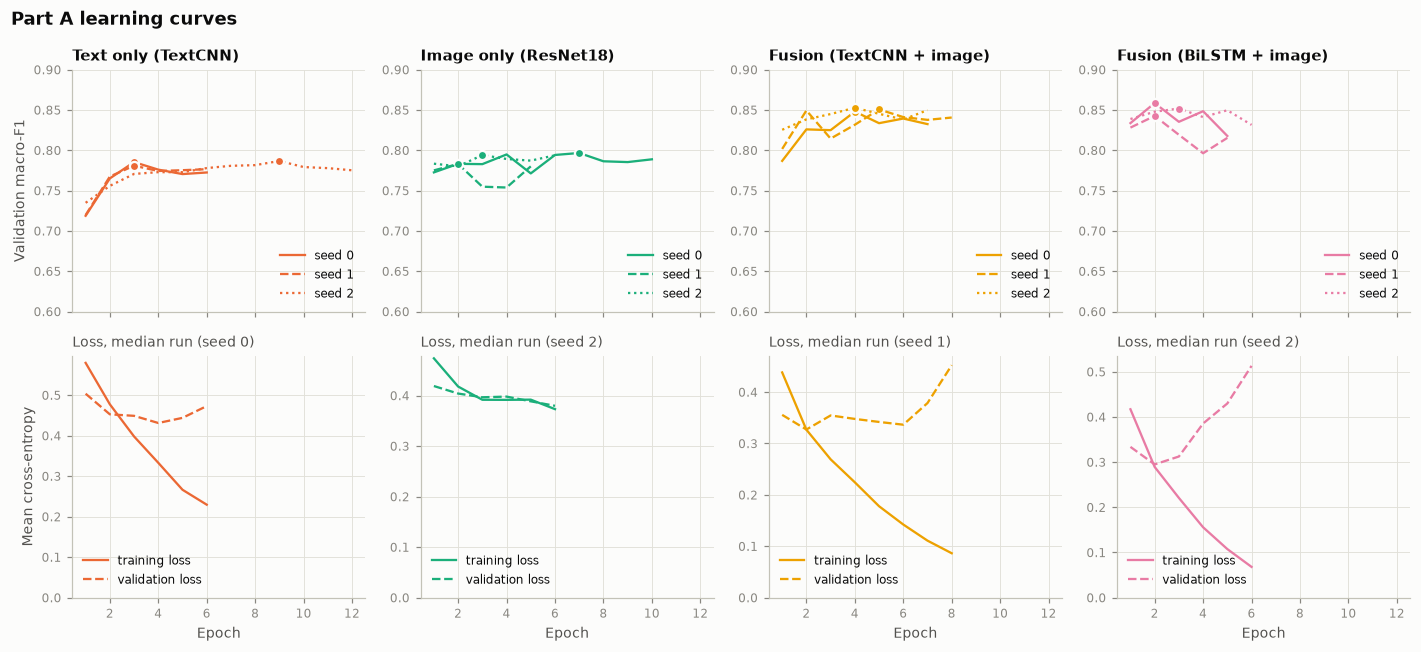

In [13]:
SEED_STYLES = {0: "-", 1: "--", 2: ":"}
fig, axes = plt.subplots(2, len(LEARNED), figsize=(13, 6), sharex=True)
for col, kind in enumerate(LEARNED):
    color = COLORS[kind]
    ax_f1, ax_loss = axes[0, col], axes[1, col]
    for r in (r for r in train_runs if r["kind"] == kind):
        epochs = pd.read_csv(r["path"] / "epochs.csv")
        ax_f1.plot(epochs["epoch"], epochs["valid_macro_f1"], SEED_STYLES[r["seed"]], color=color,
                   label=f"seed {r['seed']}")
        best = epochs.loc[epochs["epoch"] == r["selected_epoch"]]
        ax_f1.plot(best["epoch"], best["valid_macro_f1"], "o", color=color, markersize=6,
                   markeredgecolor=SURFACE, markeredgewidth=1.5)
        if r["experiment_id"] == median_run[kind]:
            ax_loss.plot(epochs["epoch"], epochs["train_loss"], "-", color=color, label="training loss")
            ax_loss.plot(epochs["epoch"], epochs["valid_loss"], "--", color=color, label="validation loss")
            ax_loss.set_title(f"Loss, median run (seed {r['seed']})", fontsize=9, fontweight="normal",
                              color=INK_2)
    ax_f1.set_title(MODELS[kind]["name"])
    ax_f1.set_ylim(0.6, 0.9)
    ax_loss.set_xlabel("Epoch")
    ax_loss.set_ylim(bottom=0)
    ax_f1.legend(loc="lower right")
    ax_loss.legend(loc="lower left")
axes[0, 0].set_ylabel("Validation macro-F1")
axes[1, 0].set_ylabel("Mean cross-entropy")
for ax in axes.flat:
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
fig.suptitle("Part A learning curves", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "learning_curves.png", bbox_inches="tight")
plt.show()

### Confusion matrices (test set, median-validation run per model)

Rows are true labels and columns are predictions. Each cell shows its count and the row percentage, which for the diagonal is that class's recall. Shading is the row percentage on a single-hue blue scale.

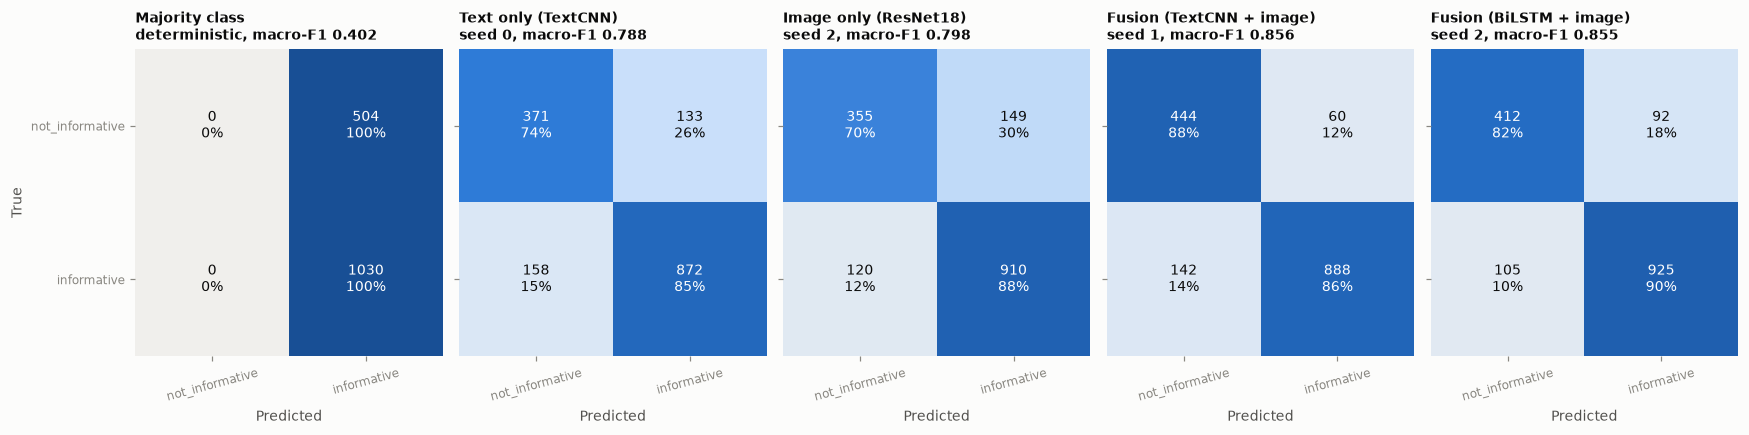

In [14]:
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

BLUES = LinearSegmentedColormap.from_list("seq_blue", ["#f0efec", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95"])
class_names = [ID_TO_LABEL[i] for i in range(NUM_CLASSES)]
median_results = results_df[results_df["median_validation_run"]].set_index("model").reindex(list(MODELS))

fig, axes = plt.subplots(1, len(MODELS), figsize=(16, 3.6))
for ax, kind in zip(axes, MODELS):
    cm = np.array(median_results.loc[kind, "confusion_matrix"])
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap=BLUES, vmin=0, vmax=1)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, f"{cm[i, j]}\n{share[i, j]:.0%}", ha="center", va="center", fontsize=9,
                    color="#ffffff" if share[i, j] > 0.6 else INK)
    seed = median_results.loc[kind, "seed"]
    ax.set_title(f"{MODELS[kind]['name']}\n{seed_label(seed)}, macro-F1 "
                 f"{median_results.loc[kind, 'test_macro_f1']:.3f}", fontsize=9)
    ax.set_xticks(range(NUM_CLASSES), class_names, rotation=15)
    ax.set_yticks(range(NUM_CLASSES), class_names if kind == "majority" else [""] * NUM_CLASSES)
    ax.set_xlabel("Predicted")
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
axes[0].set_ylabel("True")
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrices_test.png", bbox_inches="tight")
plt.show()

## Where fusion helps or fails: six test examples

This compares the median-validation runs of **text only**, **image only** and the **simple fusion (TextCNN + image)** on the test set. It runs after final evaluation, as post-hoc error analysis, and isn't used for selection.
- *Helps:* fusion is right while the unimodal models are wrong. Cases where both unimodal models are wrong come first.
- *Fails:* fusion is wrong while a unimodal model is right. Cases where both unimodal models are right come first.

Within each group, examples are ranked by fusion confidence, with at most one image per tweet.

,test examples (n=1534)
"fusion right, both unimodal wrong",15
"fusion right, exactly one unimodal wrong",311
"fusion wrong, both unimodal right",29
"fusion wrong, exactly one unimodal right",127
all three right,1006
all three wrong,46


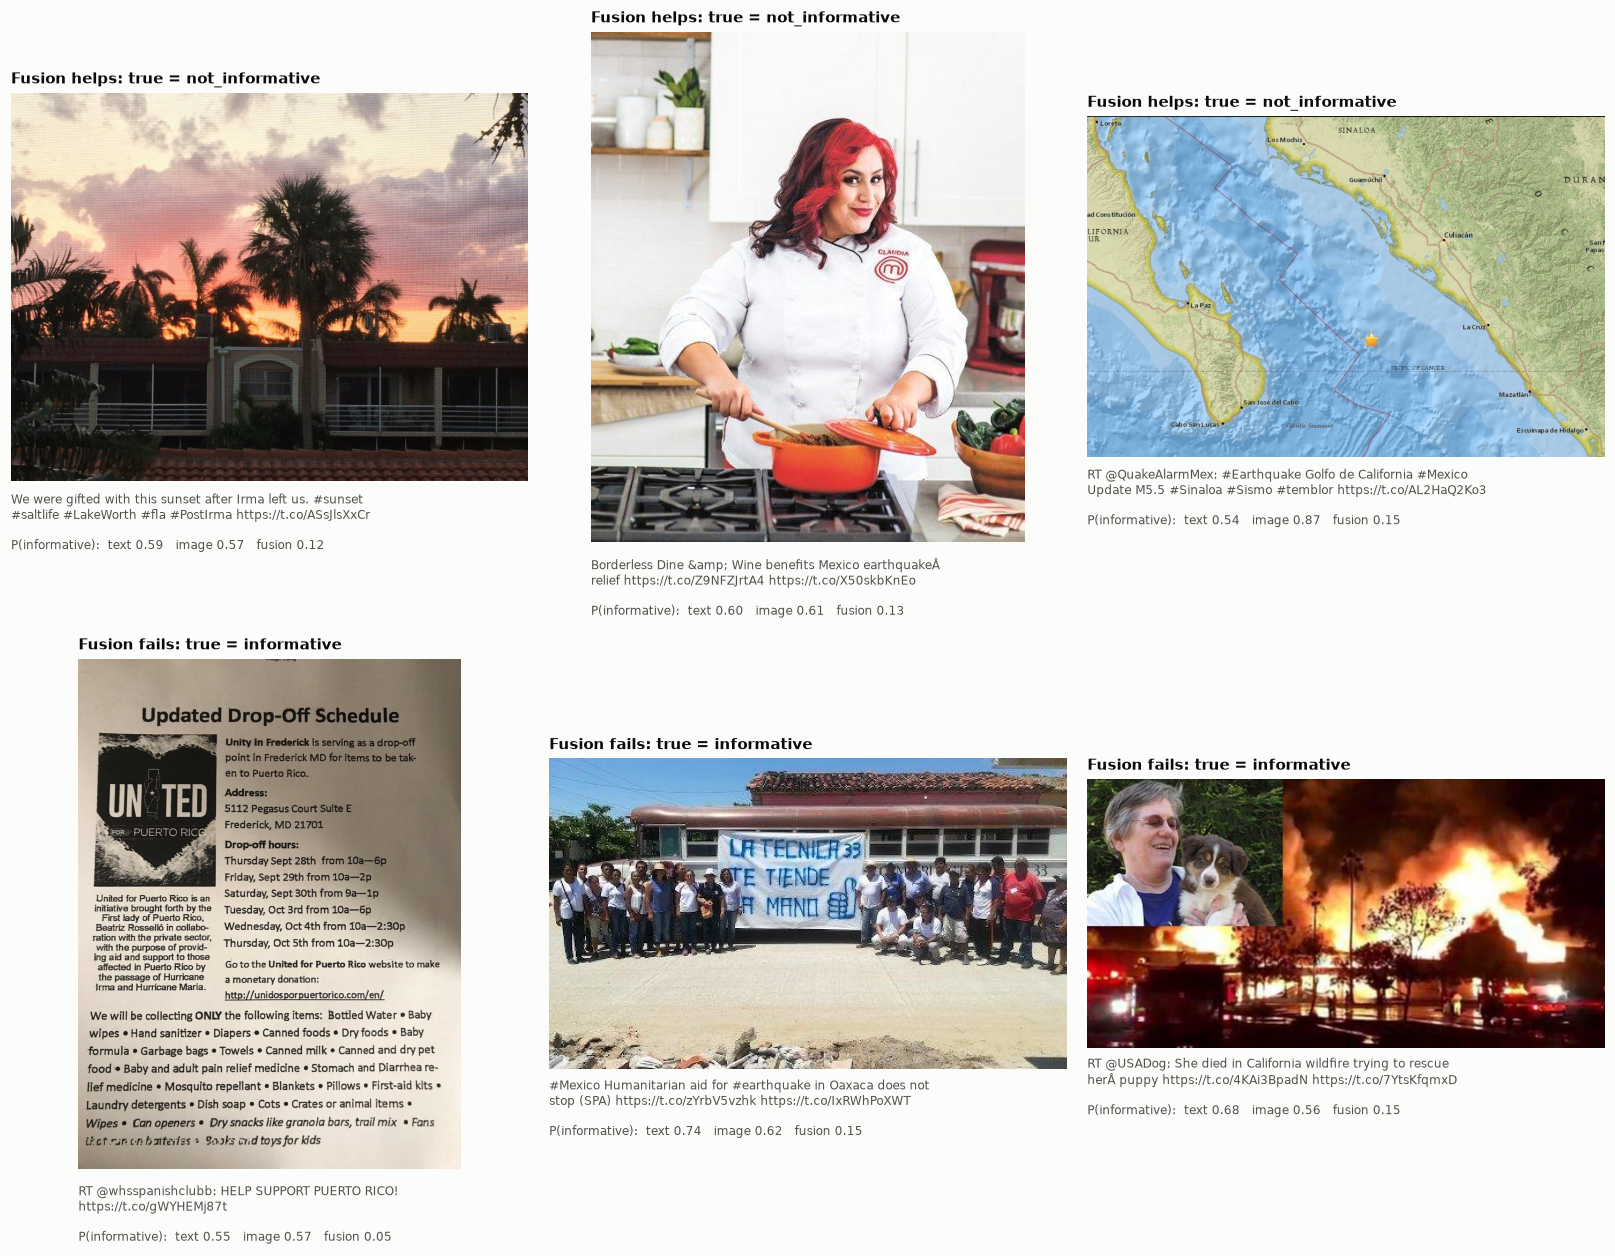

,group,tweet_id,image_id,event,true_label,label_text,label_image,p_informative_text_textcnn,p_informative_image_mlp,p_informative_fusion_textcnn
0,Fusion helps,910135455630397441,910135455630397441_0,hurricane_irma,not_informative,not_informative,not_informative,0.591,0.572,0.115
1,Fusion helps,912342429449293824,912342429449293824_0,mexico_earthquake,not_informative,not_informative,not_informative,0.603,0.608,0.132
2,Fusion helps,911682837190979585,911682837190979585_0,mexico_earthquake,not_informative,not_informative,not_informative,0.539,0.873,0.155
3,Fusion fails,915300283961479168,915300283961479168_0,hurricane_maria,informative,informative,informative,0.552,0.565,0.054
4,Fusion fails,912254680373321728,912254680373321728_0,mexico_earthquake,informative,informative,informative,0.739,0.622,0.148
5,Fusion fails,919633543474577408,919633543474577408_0,california_wildfires,informative,informative,informative,0.682,0.556,0.149


In [15]:
import textwrap

y_test = data["test"]["labels"].numpy()
p_inf = {k: test_probs[median_run[k]][:, POSITIVE].numpy() for k in ("text_textcnn", "image_mlp", "fusion_textcnn")}
correct = {k: (p >= 0.5).astype(int) == y_test for k, p in p_inf.items()}
text_ok, image_ok, fusion_ok = correct["text_textcnn"], correct["image_mlp"], correct["fusion_textcnn"]

categories = pd.Series({
    "fusion right, both unimodal wrong": int((fusion_ok & ~text_ok & ~image_ok).sum()),
    "fusion right, exactly one unimodal wrong": int((fusion_ok & (text_ok ^ image_ok)).sum()),
    "fusion wrong, both unimodal right": int((~fusion_ok & text_ok & image_ok).sum()),
    "fusion wrong, exactly one unimodal right": int((~fusion_ok & (text_ok ^ image_ok)).sum()),
    "all three right": int((fusion_ok & text_ok & image_ok).sum()),
    "all three wrong": int((~fusion_ok & ~text_ok & ~image_ok).sum()),
}, name=f"test examples (n={len(y_test)})")
display(categories.to_frame())

fusion_confidence = np.abs(p_inf["fusion_textcnn"] - 0.5)


def pick(mask_first, mask_second, n=3):
    """Up to n examples: first from mask_first, then mask_second; most confident fusion first."""
    chosen, tweets = [], set()
    for mask in (mask_first, mask_second):
        for i in np.argsort(np.where(mask, -fusion_confidence, 9.0), kind="stable"):
            if len(chosen) == n or not mask[i]:
                break
            if data["test"]["rows"][i]["tweet_id"] not in tweets:
                chosen.append(int(i))
                tweets.add(data["test"]["rows"][i]["tweet_id"])
    return chosen


helps = pick(fusion_ok & ~text_ok & ~image_ok, fusion_ok & (text_ok ^ image_ok))
fails = pick(~fusion_ok & text_ok & image_ok, ~fusion_ok & (text_ok ^ image_ok))
examples = [("Fusion helps", i) for i in helps] + [("Fusion fails", i) for i in fails]

rows_out = []
fig, axes = plt.subplots(2, 3, figsize=(15, 11.5))
for ax, (group, i) in zip(axes.flat, examples):
    row = data["test"]["rows"][i]
    with Image.open(root / row["image"]) as img:
        ax.imshow(img.convert("RGB"))
    ax.axis("off")
    ax.set_title(f"{group}: true = {row['label']}", fontsize=10)
    probs_line = "   ".join(f"{name} {p_inf[k][i]:.2f}" for name, k in
                           (("text", "text_textcnn"), ("image", "image_mlp"), ("fusion", "fusion_textcnn")))
    caption = textwrap.fill(row["tweet_text"], 60) + f"\n\nP(informative):  {probs_line}"
    ax.text(0.0, -0.03, caption, transform=ax.transAxes, va="top", ha="left", fontsize=8, color=INK_2)
    rows_out.append({"group": group, "tweet_id": row["tweet_id"], "image_id": row["image_id"],
                     "event": row["event_name"], "true_label": row["label"],
                     "label_text": row["label_text"], "label_image": row["label_image"],
                     **{f"p_informative_{k}": round(float(p_inf[k][i]), 3) for k in p_inf},
                     "tweet_text": row["tweet_text"]})
fig.tight_layout(h_pad=7)
fig.savefig(FIG_DIR / "fusion_examples.png", bbox_inches="tight")
plt.show()

examples_df = pd.DataFrame(rows_out)
examples_df.to_csv(RESULTS_DIR / "fusion_examples.csv", index=False)
display(examples_df.drop(columns="tweet_text"))

## Part A findings

1. **Both modalities beat the majority baseline by a wide margin.** The majority baseline gets 67.1% accuracy but only 0.402 macro-F1, because it never predicts *not_informative*. That is why macro-F1, not accuracy, is the headline metric. Image only (0.803 ± 0.007) beats text only (0.780 ± 0.009). The frozen ResNet18 features carry slightly more signal than a TextCNN trained from scratch on about 8.3k unique tweets.
2. **Simple fusion is clearly better than either modality.**
   - TextCNN fusion reaches 0.860 ± 0.004 macro-F1 and 87.7% accuracy.
   - It improves on image-only by +0.051, +0.056 and +0.065 for seeds 0, 1 and 2: consistent across seeds, and about ten times the seed standard deviation.
   - Informative precision and recall both rise to about 0.91.
   - The biggest change is *not_informative* recall: 88% in the median run, against 70–74% for unimodal models.
3. **Swapping TextCNN for BiLSTM in the fusion model makes no reliable difference.** BiLSTM reaches 0.862 ± 0.006 against 0.860 ± 0.004. The per-seed differences are +0.004, +0.008 and −0.008, which change sign and are smaller than the seed spread. The image branch and classifier head were held fixed, so the text encoder is the only change. The BiLSTM adds 149k parameters (+14%) yet selects an earlier epoch (2.3 against 4.3 on average) and overfits faster: its validation loss rises from epoch 2 while training loss keeps falling. With three seeds we cannot separate the two encoders.
4. **Every learned model overfits within a few epochs**, so early stopping on validation macro-F1 (patience 3) ended every run long before the 20-epoch cap: selected epochs 2–9, at most 12 epochs completed. Validation loss and validation macro-F1 do not always peak at the same epoch. For example, the median TextCNN-fusion run has its lowest validation loss at epoch 2 but its best macro-F1 at epoch 5, so selecting on loss would sometimes pick a different checkpoint.
5. **Published comparison (accuracy only).**
   - Our text-only model (80.9%) and image-only model (82.9%) are within half a point of Ofli et al.'s text CNN (80.8%) and VGG16 (83.3%).
   - Our TextCNN fusion (87.7%) is 3.3 points above their fusion (84.4%).
   - Their pretrained word vectors, larger image network, preprocessing and tuning all differ from ours, so this gap should not be read as one method being better. It does show that the brief's affordable setup, with a frozen encoder and cached features, loses little.
6. **Training cost is tiny.** On cached features each run takes 1–4 s on the RTX 5060 Ti. Every learned model has 0.16–1.19M trainable parameters; the image-only model is the smallest and cheapest.

Each run saves these files under `logs/runs/<experiment_id>/`:
- `config.json`, registered before the run starts
- `summary.json`
- `energy.csv`, one final total
- `energy_timeseries.csv`, cumulative snapshots
- `codecarbon.log`
- TensorBoard events

`summary.json` already holds:
- whether each of CPU, GPU and RAM was measured or estimated
- energy and emissions low/high bounds
- the carbon-intensity value, type and source
- PUE and failure reasons

**Do not sum the cumulative time-series rows:** use the summaries for run totals.

Run the cell below after any batch of runs. It rebuilds the submitted experiment log in `logs/`:
- `run_log.csv`, one row per run
- `stage_summary.csv` (Table 1)
- `model_summary.csv` (Table 2)
- `aggregate_summary.json`


In [16]:
from scripts.aggregate_runs import aggregate

log_summary = aggregate("logs/runs", "logs")
print(json.dumps({key: log_summary[key] for key in (
    "runs", "runs_by_run_type", "runs_by_status", "runtime_seconds_total",
    "energy_kwh_total", "energy_kwh_low_total", "energy_kwh_high_total",
    "emissions_kgco2e_total", "warnings",
)}, indent=2))

{
  "runs": 34,
  "runs_by_run_type": {
    "debug": 6,
    "exploratory": 0,
    "final": 28,
    "failed": 0
  },
  "runs_by_status": {
    "completed": 22,
    "early-stopped": 12
  },
  "runtime_seconds_total": 151.1398625989982,
  "energy_kwh_total": 0.004692883287729269,
  "energy_kwh_low_total": 0.003759973310110431,
  "energy_kwh_high_total": 0.006265435078570551,
  "emissions_kgco2e_total": 0.0005725317611029709,
  "warnings": []
}


## Environmental impact of Part A model development

Figures and tables for the report's *Environmental Impact of Model Development* section, Part A only, built from `logs/run_log.csv`:
- Energy is CodeCarbon-tracked over the whole machine. CPU (RAPL) and GPU (NVML) are measured; RAM is estimated.
- Emissions use 122 gCO₂/kWh, the NESO Great Britain average for the 12 months to Oct 2026.
- Whiskers show the documented low/high uncertainty range (see `templates/measurement_method.json`).
- Figures use Wh (1 Wh = 0.001 kWh) for readability; tables and logs use kWh and kgCO₂e.

Idle machine draw: 76.1 W  (CPU 35.9 W, GPU 19.8 W, RAM 20.0 W estimated)


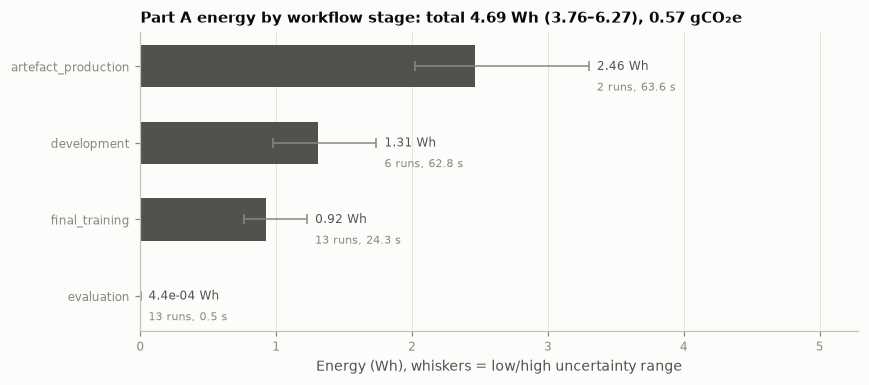

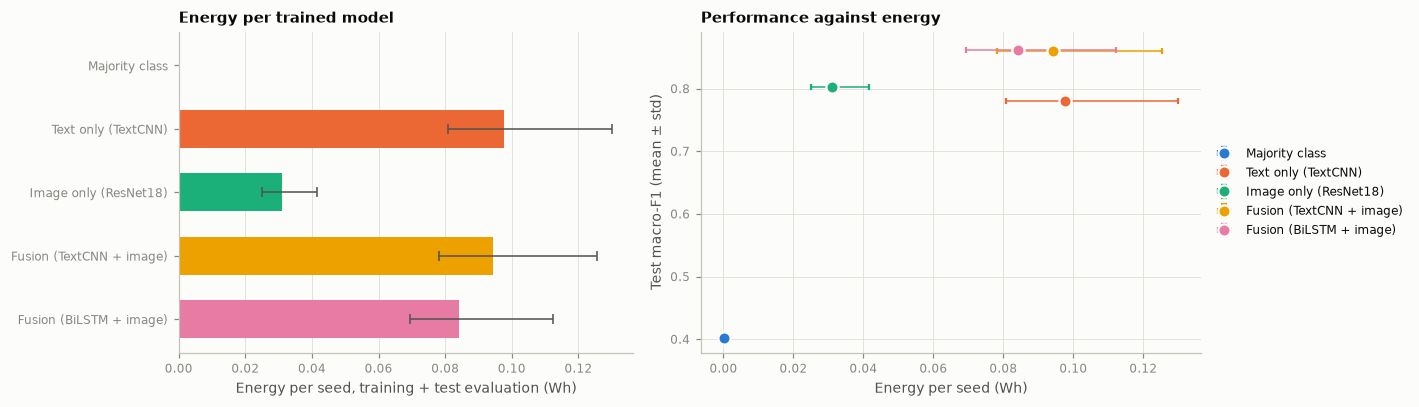

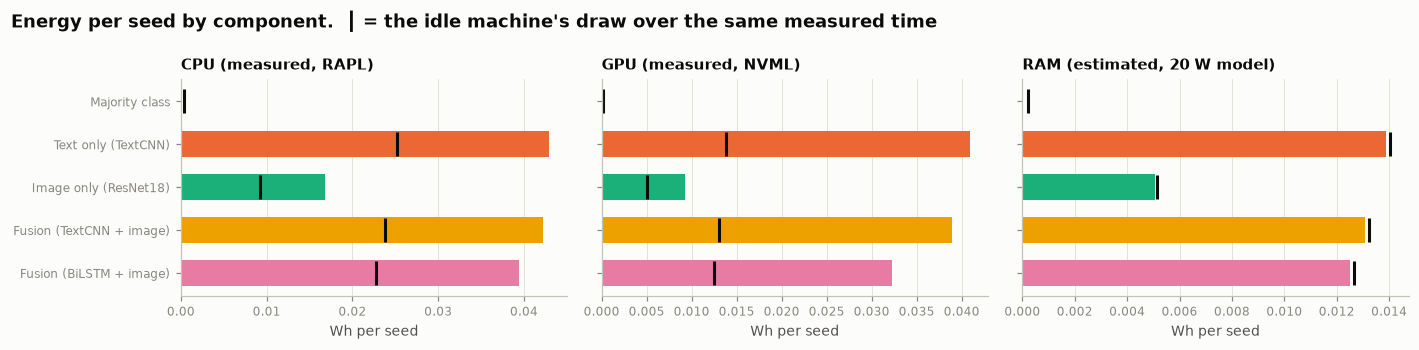

Model,Seeds,Test macro-F1,Energy per seed (kWh),"Energy, all seeds (kWh)",Emissions per seed (kgCO2e),Macro-F1 per kWh,Macro-F1 per kgCO2e,Marginal gCO2e per +0.01 macro-F1 vs majority,Idle-draw share of energy
Majority class,1,0.401700,0.000000,0.000000,0.0000000,-,-,-,-
Text only (TextCNN),3,0.779900,0.000098,0.000293,0.0000119,"7,988","65,478",0.0003,55%
Image only (ResNet18),3,0.803200,0.000031,0.000093,0.0000038,"25,839","211,792",0.0001,63%
Fusion (TextCNN + image),3,0.860400,0.000094,0.000283,0.0000115,"9,132","74,855",0.0003,53%
Fusion (BiLSTM + image),3,0.861800,0.000084,0.000253,0.0000103,"10,230","83,855",0.0002,57%


Majority baseline: well under 0.1 s of compute, so its efficiency ratios and idle share are not meaningful.
15 runs lasted under 0.2 s and recorded zero GPU energy: the NVML energy counter does not update within such short intervals, so these runs are under-measured (negligible in absolute terms).


In [19]:
run_log = pd.read_csv("logs/run_log.csv")
run_log = run_log[run_log["coursework_part"] == "A"].set_index("experiment_id")
stage_table = pd.read_csv("logs/stage_summary.csv").set_index("stage")

idle = run_log[run_log["activity"] == "idle_baseline"].iloc[-1]
idle_w = {c: idle[f"{c}_power_w_avg"] for c in ("cpu", "gpu", "ram")}
idle_total_w = idle["energy_kwh"] * 3.6e6 / idle["tracker_duration_seconds"]
print(f"Idle machine draw: {idle_total_w:.1f} W  (CPU {idle_w['cpu']:.1f} W, GPU {idle_w['gpu']:.1f} W, "
      f"RAM {idle_w['ram']:.1f} W estimated)")

# --- Figure 1: energy by workflow stage, with the uncertainty range -------------------------
stages = stage_table.drop(index="TOTAL")
stages = stages[stages["runs"] > 0].sort_values("energy_kwh")
fig, ax = plt.subplots(figsize=(8, 0.6 * len(stages) + 1.2))
wh = stages["energy_kwh"] * 1000
ax.barh(stages.index, wh, height=0.55, color=INK_2)
ax.errorbar(wh, stages.index, xerr=[wh - stages["energy_kwh_low"] * 1000, stages["energy_kwh_high"] * 1000 - wh],
            fmt="none", ecolor=MUTED, elinewidth=1, capsize=3)
for y, (name, r) in enumerate(stages.iterrows()):
    value = r["energy_kwh"] * 1000
    ax.text(r["energy_kwh_high"] * 1000, y, f"  {value:.2f} Wh" if value >= 0.01 else f"  {value:.1e} Wh",
            va="center", fontsize=8, color=INK_2)
    ax.text(r["energy_kwh_high"] * 1000, y - 0.28, f"  {int(r['runs'])} runs, {r['runtime_seconds']:.1f} s",
            va="center", fontsize=7, color=MUTED)
ax.set_xlabel("Energy (Wh), whiskers = low/high uncertainty range")
ax.set_xlim(0, stages["energy_kwh_high"].max() * 1000 * 1.6)
ax.grid(axis="y", visible=False)
total = stage_table.loc["TOTAL"]
ax.set_title(f"Part A energy by workflow stage: total {total['energy_kwh'] * 1000:.2f} Wh "
             f"({total['energy_kwh_low'] * 1000:.2f}–{total['energy_kwh_high'] * 1000:.2f}), "
             f"{total['emissions_kgco2e'] * 1000:.2f} gCO₂e")
fig.tight_layout()
fig.savefig(FIG_DIR / "energy_by_stage.png", bbox_inches="tight")
plt.show()

# --- Per-model energy (training + linked test evaluation) per seed --------------------------
for col in ("energy_kwh_low", "energy_kwh_high", "emissions_kgco2e_low", "emissions_kgco2e_high",
            "cpu_energy_kwh", "gpu_energy_kwh", "ram_energy_kwh"):
    results_df[col] = (run_log.loc[results_df["train_experiment_id"], col].to_numpy()
                       + run_log.loc[results_df["eval_experiment_id"], col].to_numpy())
# Measured interval (tracker_duration_seconds), so idle comparisons match what the energy covers.
results_df["measured_s"] = (run_log.loc[results_df["train_experiment_id"], "tracker_duration_seconds"].to_numpy()
                            + run_log.loc[results_df["eval_experiment_id"], "tracker_duration_seconds"].to_numpy())
per_model = results_df.groupby("model", sort=False).agg(
    seeds=("model", "size"), f1=("test_macro_f1", "mean"), f1_std=("test_macro_f1", "std"),
    energy=("energy_kwh", "mean"), energy_low=("energy_kwh_low", "mean"), energy_high=("energy_kwh_high", "mean"),
    emissions=("emissions_kgco2e", "mean"), cpu=("cpu_energy_kwh", "mean"), gpu=("gpu_energy_kwh", "mean"),
    ram=("ram_energy_kwh", "mean"), measured_s=("measured_s", "mean"), total_energy=("energy_kwh", "sum"),
).reindex(list(MODELS))

# --- Figure 2: energy per seed and macro-F1 against energy ----------------------------------
fig, (ax_e, ax_s) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.1]})
names = [MODELS[k]["name"] for k in MODELS]
y = np.arange(len(MODELS))
ax_e.barh(y, per_model["energy"] * 1000, height=0.6, color=[COLORS[k] for k in MODELS])
ax_e.errorbar(per_model["energy"] * 1000, y,
              xerr=[(per_model["energy"] - per_model["energy_low"]) * 1000,
                    (per_model["energy_high"] - per_model["energy"]) * 1000],
              fmt="none", ecolor=INK_2, elinewidth=1, capsize=3)
ax_e.set_yticks(y, names)
ax_e.invert_yaxis()
ax_e.grid(axis="y", visible=False)
ax_e.set_xlabel("Energy per seed, training + test evaluation (Wh)")
ax_e.set_title("Energy per trained model")
for kind in MODELS:
    r = per_model.loc[kind]
    ax_s.errorbar(r["energy"] * 1000, r["f1"], yerr=0 if pd.isna(r["f1_std"]) else r["f1_std"],
                  xerr=[[(r["energy"] - r["energy_low"]) * 1000], [(r["energy_high"] - r["energy"]) * 1000]],
                  fmt="o", color=COLORS[kind], markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5,
                  elinewidth=1, capsize=2, label=MODELS[kind]["name"])
ax_s.set_xlabel("Energy per seed (Wh)")
ax_s.set_ylabel("Test macro-F1 (mean ± std)")
ax_s.set_title("Performance against energy")
ax_s.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.tight_layout()
fig.savefig(FIG_DIR / "energy_vs_performance.png", bbox_inches="tight")
plt.show()

# --- Figure 3: where the energy goes (CPU / GPU / RAM), with the idle-draw equivalent -------
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, comp, label in zip(axes, ("cpu", "gpu", "ram"), ("CPU (measured, RAPL)", "GPU (measured, NVML)",
                                                          "RAM (estimated, 20 W model)")):
    ax.barh(y, per_model[comp] * 1000, height=0.6, color=[COLORS[k] for k in MODELS])
    idle_equiv = idle_w[comp] * per_model["measured_s"] / 3600
    ax.plot(idle_equiv, y, "|", color=INK, markersize=16, markeredgewidth=2)
    ax.set_title(label)
    ax.set_xlabel("Wh per seed")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, names)
axes[0].invert_yaxis()
fig.suptitle("Energy per seed by component.  ┃ = the idle machine's draw over the same measured time",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "energy_by_component.png", bbox_inches="tight")
plt.show()

# --- Table: performance-aware indicators -----------------------------------------------------
base = per_model.loc["majority"]
indicators = pd.DataFrame({
    "Model": names,
    "Seeds": per_model["seeds"].astype(int).to_numpy(),
    "Test macro-F1": per_model["f1"].round(4).to_numpy(),
    "Energy per seed (kWh)": per_model["energy"].map("{:.6f}".format).to_numpy(),
    "Energy, all seeds (kWh)": per_model["total_energy"].map("{:.6f}".format).to_numpy(),
    "Emissions per seed (kgCO2e)": per_model["emissions"].map("{:.7f}".format).to_numpy(),
    "Macro-F1 per kWh": ["-" if k == "majority" else f"{r['f1'] / r['energy']:,.0f}" for k, r in per_model.iterrows()],
    "Macro-F1 per kgCO2e": ["-" if k == "majority" else f"{r['f1'] / r['emissions']:,.0f}"
                            for k, r in per_model.iterrows()],
    "Marginal gCO2e per +0.01 macro-F1 vs majority": [
        "-" if k == "majority" else
        f"{1000 * (r['emissions'] - base['emissions']) / ((r['f1'] - base['f1']) * 100):.4f}"
        for k, r in per_model.iterrows()],
    "Idle-draw share of energy": ["-" if k == "majority" else
                                  f"{idle_total_w * r['measured_s'] / 3600 / (r['energy'] * 1000):.0%}"
                                  for k, r in per_model.iterrows()],
})
indicators.to_csv(RESULTS_DIR / "environmental_indicators.csv", index=False)
display(indicators.style.hide(axis="index"))
print("Majority baseline: well under 0.1 s of compute, so its efficiency ratios and idle share are not meaningful.")
short = run_log[(run_log["tracker_duration_seconds"] < 0.2) & (run_log["gpu_energy_kwh"] == 0)]
print(f"{len(short)} runs lasted under 0.2 s and recorded zero GPU energy: the NVML energy counter does not "
      "update within such short intervals, so these runs are under-measured (negligible in absolute terms).")